# TGLF and GFTM error against WIDTH per NBASIS on the KBM hypercubes, with the Gaussian-mismatch theory

Fusion_PhD-qp5.27 (dataset slides for the 2 Nov talk). No new runs. The GS2-KBM population of the `kbm_8d` Latin hypercubes of
SPR-045 and M1, the only population with fixed-width TGLF data per NBASIS:
- **TGLF** `TGLF/Runs/kbm_tglf_nbasis/<db>/nb<N>_nx32_fp0p0_<w>`: NBASIS_MAX 4/8/16/24/32, NXGRID 32, FILTER 0 (the FILTER of the
  single-mode scan, qp5.26), 24 widths 0.2–4.0 (`results/tglf_find_width`, `results/tglf_quadrature_extent`).
- **GFTM** (stock field solve) `GFTM/Runs/LATIN_HYPERCUBE/<db>/kbm_8d/{wo_f05_<w>, qx_f05_<w>_nb<N>_nx<X>}`: NBASIS 11/22/27/43/59 at
  NXGRID 17/28/33/49/65, FILTER 0.5 (`results/gftm_quadrature_extent` fig5).

**Parity.** The SPR-045 `kbm_8d` GS2 decks force ballooning parity (`def_parity=.true.`, `even=.true.`), so the classifier's $T < 0.05$
step is imposed there, not measured. M1 `kbm_8d` is free parity (`docs/gyro_data_runs.md`).

**Theory overlay.** The relative $L^2$ error of the first $N$ Hermite functions $h_n(\theta/W)$ on a Gaussian of width mismatch $s$
(`kbm_width_collapse.ipynb`): $\epsilon_N(s) = [1 - \sqrt{1-r^2}\sum_{k<\lceil N/2\rceil}\binom{2k}{k}(r^2/4)^k]^{1/2}$,
$r = (s^2-1)/(s^2+1)$, with $s = W/W^*$ and $W^* = \theta_{95}/2.772$ the Gaussian-matched width of the population's median GS2
$\theta_{95}(\phi)$ (no fitted constant). **Assumption:** the median relative eigenvalue error tracks $\epsilon_N$; the overlay shows
the predicted shape and where it should sit, not a fit.

In [1]:
from pathlib import Path
import os
import json
import re
from math import comb
from multiprocessing import get_context
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.diagnostics.extent import Extent
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams.update({"font.size": 17, "axes.labelsize": 19, "axes.titlesize": 19, "legend.fontsize": 13,
                     "xtick.labelsize": 16, "ytick.labelsize": 16})     # slide-ready
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

plots_dir = ROOT / "Plots" / "kbm_width_collapse"
plots_dir.mkdir(parents=True, exist_ok=True)
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
lhc = data_root / "GS2" / "Runs" / "LATIN_HYPERCUBE"
databases = ["SPR-045", "M1"]
tglf_nbasis = [4, 8, 16, 24, 32]                        # NXGRID 32
gftm_sections = {11: 17, 22: 28, 27: 33, 43: 49, 59: 65}  # NBASIS: NXGRID
fraction = 0.95
gaussian_c = 1 / (2 * 1.96 / np.sqrt(2))
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))
tolerance_cut = 0.05
tglf_filter = float(os.environ.get("TGLF_FILTER", "2"))   # 2 (TGLF default, main), 0 (backup, the FILTER of qp5.26) or -0.1
tglf_tag = {0.0: "fp0p0", 2.0: "fp2p0", -0.1: "fm0p1"}[tglf_filter]
suffix = "" if tglf_filter == 2 else f"_tglf_{tglf_tag}"


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()


def gaussian_error(s, nbasis):
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    kept = sum(comb(2 * k, k) * (r_squared / 4) ** k for k in range((nbasis + 1) // 2))
    return np.sqrt(np.clip(1 - np.sqrt(1 - r_squared) * kept, 0, None))

pyrokinetics 0.9.2.dev153+g3290c692


## Dataset selection: the user's classifier, step by step
`mode_classification` (docs/mode_filtering.md): KBM = $\omega > 0$ (ion direction), $0.25 < \chi_e/\chi_i < 4$, $T < 0.05$; then
$\gamma > 0$ and converged (`growth_rate_tolerance` < 0.05). Counts are cumulative (each step applied on top of the previous ones).
**Figure population = KBM and $\gamma > 0$** (SPR-045 119, M1 161), exactly as `tglf_find_width` (qp5.21), so every dataset figure shares it; the
`converged` column is a supplement only (not applied).
`kbm_8d`: indicators from the final-time `pyro_cube` (complex $A_\parallel$), $\gamma$, $\omega$ and tolerance from the tail-averaged
`pyro_cube_avg` (as `tglf_find_width`). `kbm_free`: the cube's saved `tearing_parameter` (as `results/gftm_galerkin_field/population.py`).

In [2]:
def step_counts(database, cube, omega, chi_ratio, tearing, gamma, tol):
    steps = {"loaded": np.ones(len(gamma), bool), "omega>0": omega > 0,
             "0.25<chi_e/chi_i<4": (mc.CHI_KBM[0] < chi_ratio) & (chi_ratio < mc.CHI_KBM[1]), "T<0.05": tearing < mc.T_BAL,
             "gamma>0": np.isfinite(gamma) & (gamma > 0), "converged (supplement)": tol < tolerance_cut}
    keep, row = np.ones(len(gamma), bool), dict(database=database, cube=cube)
    for step, passed in steps.items():
        keep &= passed
        row[step] = int(keep.sum())
    return row, keep


selection, gs2 = [], {}
for database in databases:
    gs2_dir = lhc / database / "kbm_8d"
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gs2_avg = gs2_avg_scan.gk_output.data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_scan.gk_output.data.sample_name.values.astype(str) == names).all()
    indicators = mc.indicators(gs2_scan, gs2_scan.gk_output.data)
    gamma_gs2 = gs2_avg.growth_rate.pint.dequantify().values.ravel()
    row, keep = step_counts(database, "kbm_8d", indicators["omega"].values, indicators["chi_ratio"].values, indicators["T"].values,
                            gamma_gs2, gs2_avg.growth_rate_tolerance.pint.dequantify().values.ravel())
    keep = (np.asarray(mc.classify(indicators)) == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0)   # qp5.21's population
    assert keep.sum() == row["gamma>0"]
    selection.append(row)
    phi = gs2_scan.gk_output.data.eigenfunctions.sel(field="phi").pint.dequantify().transpose("sample", "theta")
    theta95 = np.array([float(Extent._compute((np.abs(phi.isel(sample=i)) ** 2).dropna("theta"), fraction)[0]) for i in np.flatnonzero(keep)])
    gs2[database] = dict(names=names[keep], gamma=gamma_gs2[keep], omega=gs2_avg.mode_frequency.pint.dequantify().values.ravel()[keep],
                         units=re.sub(r"_pyroscan_base\d+", "", str(gs2_avg.growth_rate.data.units)), theta95=theta95)

for database in ["R3", "M1", "R4"]:
    gs2_scan = PyroHypercube(pyroscan_json=lhc / database / "kbm_free" / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=lhc / database / "kbm_free" / "pyroscan.nc")
    gs2_output = gs2_scan.gk_output.data
    heat = gs2_output["heat"].sum("field").pint.dequantify()
    particle = gs2_output["particle"].sum("field").pint.dequantify()
    species = [gs2_scan.sample_pyro(i).local_species for i in range(gs2_output.sizes["sample"])]
    chi = {}
    for name in gs2_output.species.values.astype(str):
        temp, dens, inverse_lt = (np.array([float(getattr(s[name], attr).m) for s in species]) for attr in ("temp", "dens", "inverse_lt"))
        # chi_s = (Q_s - 1.5 T_s Gamma_s) / (n_s T_s a/L_Ts), as mode_classification.indicators
        chi[name] = (heat.sel(species=name).values - 1.5 * temp * particle.sel(species=name).values, dens * temp * inverse_lt)
    ions = [name for name in chi if name != "electron"]
    chi_ratio = (chi["electron"][0] / chi["electron"][1]) / (sum(chi[s][0] for s in ions) / sum(chi[s][1] for s in ions))
    row, keep = step_counts(database, "kbm_free", mc.ION_DIRECTION * gs2_output.mode_frequency.pint.dequantify().values.ravel(), chi_ratio,
                            gs2_output.tearing_parameter.values.ravel(), gs2_output.growth_rate.pint.dequantify().values.ravel(),
                            gs2_output.growth_rate_tolerance.pint.dequantify().values.ravel())
    selection.append(row)
selection = pd.DataFrame(selection)
print(selection.to_string(index=False))

database     cube  loaded  omega>0  0.25<chi_e/chi_i<4  T<0.05  gamma>0  converged (supplement)
 SPR-045   kbm_8d     300      167                 126     125      119                      76
      M1   kbm_8d     300      216                 167     167      161                     119
      R3 kbm_free    1000      398                 236     215      202                     187
      M1 kbm_free    1000      375                 174     174      155                     140
      R4 kbm_free    1000      456                 270     252      220                     208


## TGLF and GFTM leaves
TGLF: one `PyroHypercube` per leaf; WIDTH is the source `wo_<w>` deck's own, NBASIS_MAX and FILTER are GyroRun's `code_flags`
(audited 216 000/216 000, `docs/gyro_data_runs.md`). GFTM: the `pyroscan.nc`/`cube.nc` of each leaf through `PyroScanGKOutput`, as
`gftm_quadrature_extent.ipynb` (the older `wo_f05` leaves have no `pyroscan.json`). Dominant mode = argmax $\gamma$ over modes; no
unstable mode = $\gamma$ 0, $\omega$ 0 (a miss counts as a 100% $\gamma$ error).

In [3]:
def dominant(output, database):
    output = output.set_index(sample="sample_name").sel(sample=gs2[database]["names"])
    assert re.sub(r"_pyroscan_base\d+", "", str(output.growth_rate.data.units)) == gs2[database]["units"], "normalisations differ"
    growth = output.growth_rate.pint.dequantify().fillna(-np.inf).transpose("sample", "mode")
    mode = growth.argmax("mode")
    gamma = growth.isel(mode=mode).clip(min=0).values
    omega = output.mode_frequency.pint.dequantify().transpose("sample", "mode").isel(mode=mode).values
    return gamma, np.where(gamma > 0, omega, 0.0)


def load_tglf(leaf):
    database = leaf.parent.name
    tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    assert float(flags["FILTER"]) == tglf_filter and int(flags["NXGRID"]) == 32 and leaf.name.startswith(f"nb{flags['NBASIS_MAX']}_nx32_{tglf_tag}_")
    gamma, omega = dominant(tglf_scan.gk_output.data, database)
    return pd.DataFrame(dict(code="TGLF", database=database, nbasis=int(flags["NBASIS_MAX"]), width=round(float(tglf_scan.base_pyro.gk_input.data["width"]), 4),
                             sample=gs2[database]["names"], gamma=gamma, omega=omega))


def load_gftm(leaf):
    database = leaf.parent.parent.name
    nbasis = 22 if leaf.name.startswith("wo_f05_") else int(leaf.name.split("_nb")[1].split("_")[0])
    netcdf = leaf / "pyro_cube" / "cube.nc" if (leaf / "pyro_cube" / "cube.nc").is_file() else leaf / "pyroscan.nc"
    gamma, omega = dominant(PyroScanGKOutput.from_netcdf(netcdf).data, database)
    return pd.DataFrame(dict(code="GFTM", database=database, nbasis=nbasis, width=round(float(leaf.name.split("_")[2][1:].replace("p", ".")), 4),
                             sample=gs2[database]["names"], gamma=gamma, omega=omega))


tglf_leaves = [leaf for database in databases for nbasis in tglf_nbasis
               for leaf in sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_nbasis" / database).glob(f"nb{nbasis}_nx32_{tglf_tag}_*"))]
gftm_dir = lambda database: data_root / "GFTM" / "Runs" / "LATIN_HYPERCUBE" / database / "kbm_8d"
gftm_leaves = [leaf for database in databases for leaf in sorted(gftm_dir(database).glob("wo_f05_w*")) +
               [leaf for nbasis, nxgrid in gftm_sections.items() if nbasis != 22 for leaf in sorted(gftm_dir(database).glob(f"qx_f05_w*_nb{nbasis}_nx{nxgrid}"))]]
with get_context("fork").Pool(n_workers) as pool:
    runs = pd.concat(pool.map(load_tglf, tglf_leaves, chunksize=2) + pool.map(load_gftm, gftm_leaves, chunksize=2), ignore_index=True)
print(runs.groupby(["code", "database", "nbasis"]).width.nunique().unstack().to_string())

nbasis           4     8     11    16    22    24    27    32    43    59
code database                                                            
GFTM M1         NaN   NaN  66.0   NaN  59.0   NaN  66.0   NaN  66.0  66.0
     SPR-045    NaN   NaN  66.0   NaN  59.0   NaN  66.0   NaN  66.0  66.0
TGLF M1        24.0  24.0   NaN  24.0   NaN  24.0   NaN  24.0   NaN   NaN
     SPR-045   24.0  24.0   NaN  24.0   NaN  24.0   NaN  24.0   NaN   NaN


## Error against WIDTH per NBASIS (TGLF top row, GFTM bottom row)
Median over the population of $|\gamma/\gamma_{\rm GS2} - 1|$ and $|\omega - \omega_{\rm GS2}|/|\omega_{\rm GS2}|$, one line per NBASIS. Dotted:
the Gaussian $\epsilon_N(W/W^*)$ at the same $N$; grey vertical line: $W^*$. Validity window: the contiguous range of grid widths around
each line's minimum where the median stays below 10% and 20%.

W* (min of the top-NBASIS line): {('GFTM', 'M1'): np.float64(0.5279), ('GFTM', 'SPR-045'): np.float64(0.5279), ('TGLF', 'M1'): np.float64(4.0), ('TGLF', 'SPR-045'): np.float64(4.0)} | floor (panel min median error): {('GFTM', 'M1'): np.float64(0.079), ('GFTM', 'SPR-045'): np.float64(0.177), ('TGLF', 'M1'): np.float64(0.554), ('TGLF', 'SPR-045'): np.float64(0.632)}
for reference, Gaussian-matched W* = theta95/2.772 of the median GS2 theta95: {'SPR-045': np.float64(0.986), 'M1': np.float64(0.961)}
samples with a top-NBASIS mode at W*: {('GFTM', 'M1'): 161, ('GFTM', 'SPR-045'): 119, ('TGLF', 'M1'): 161, ('TGLF', 'SPR-045'): 119}


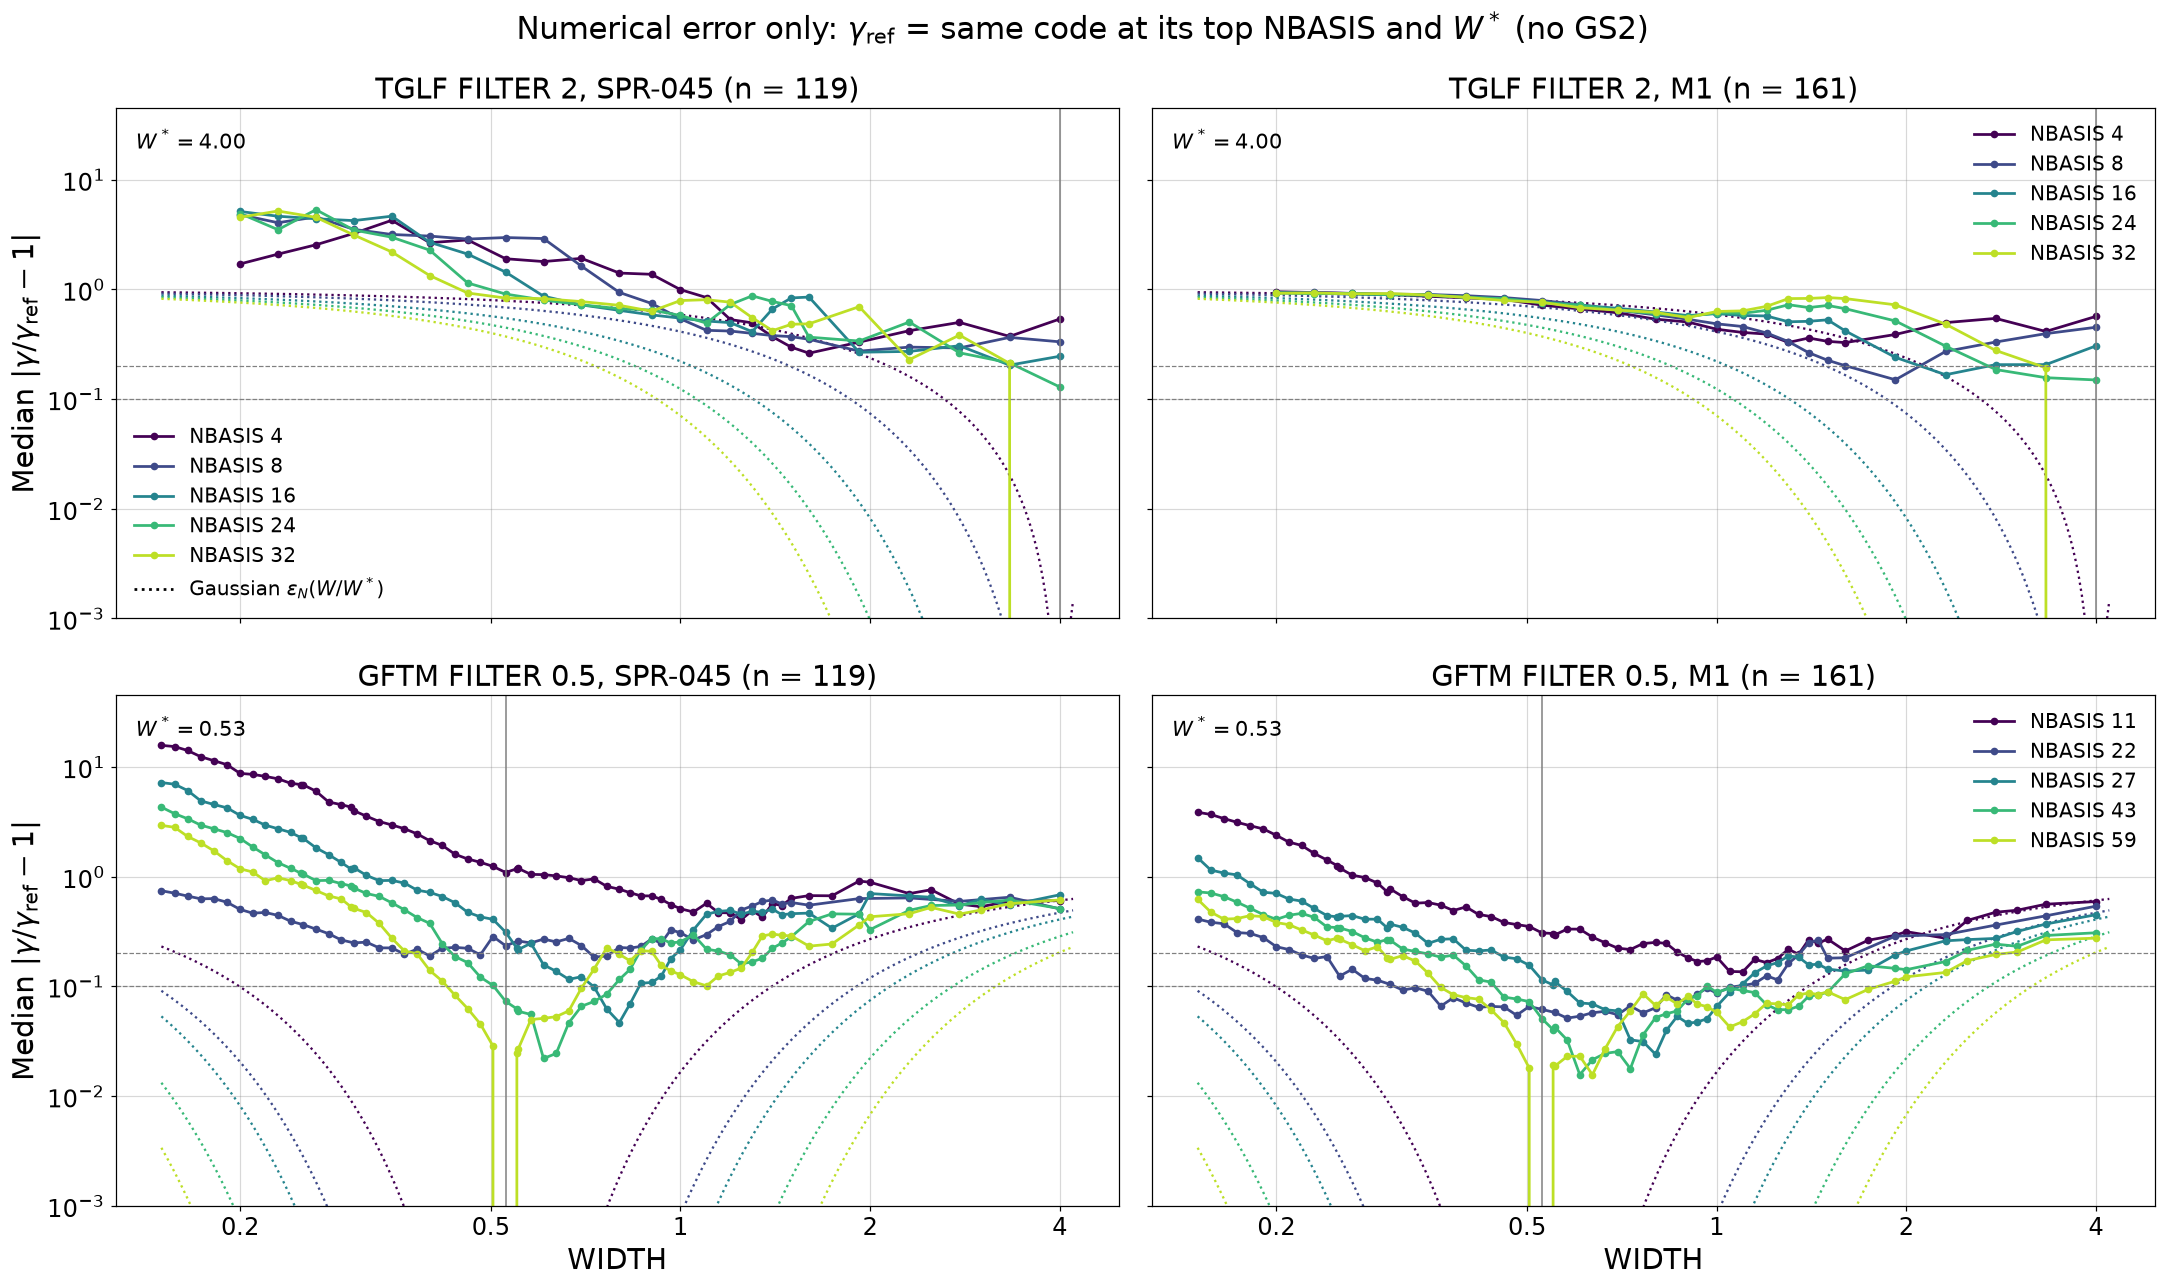

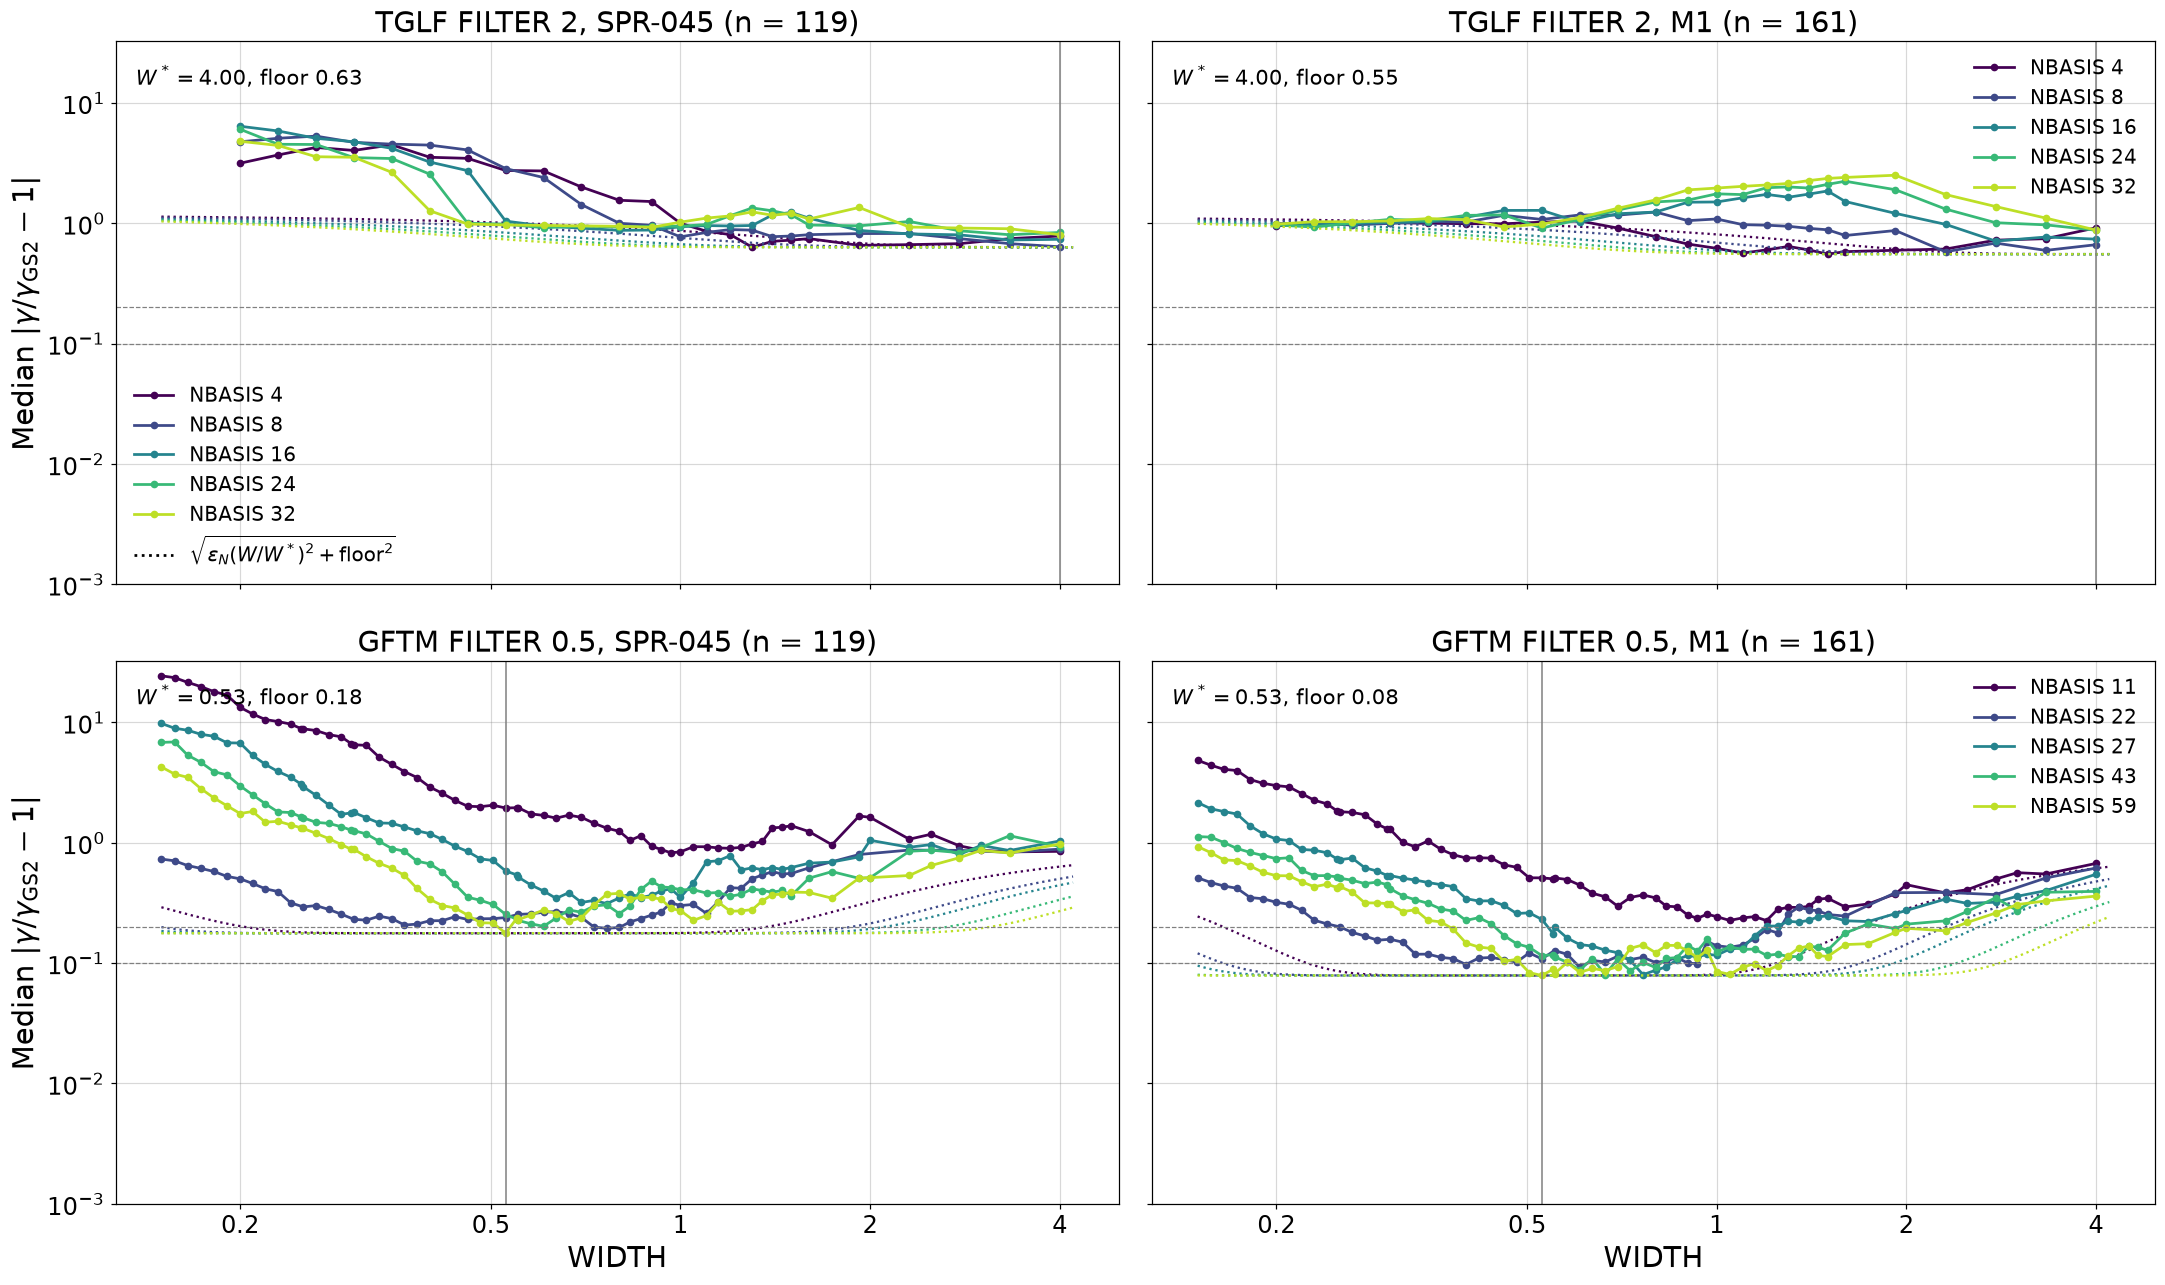

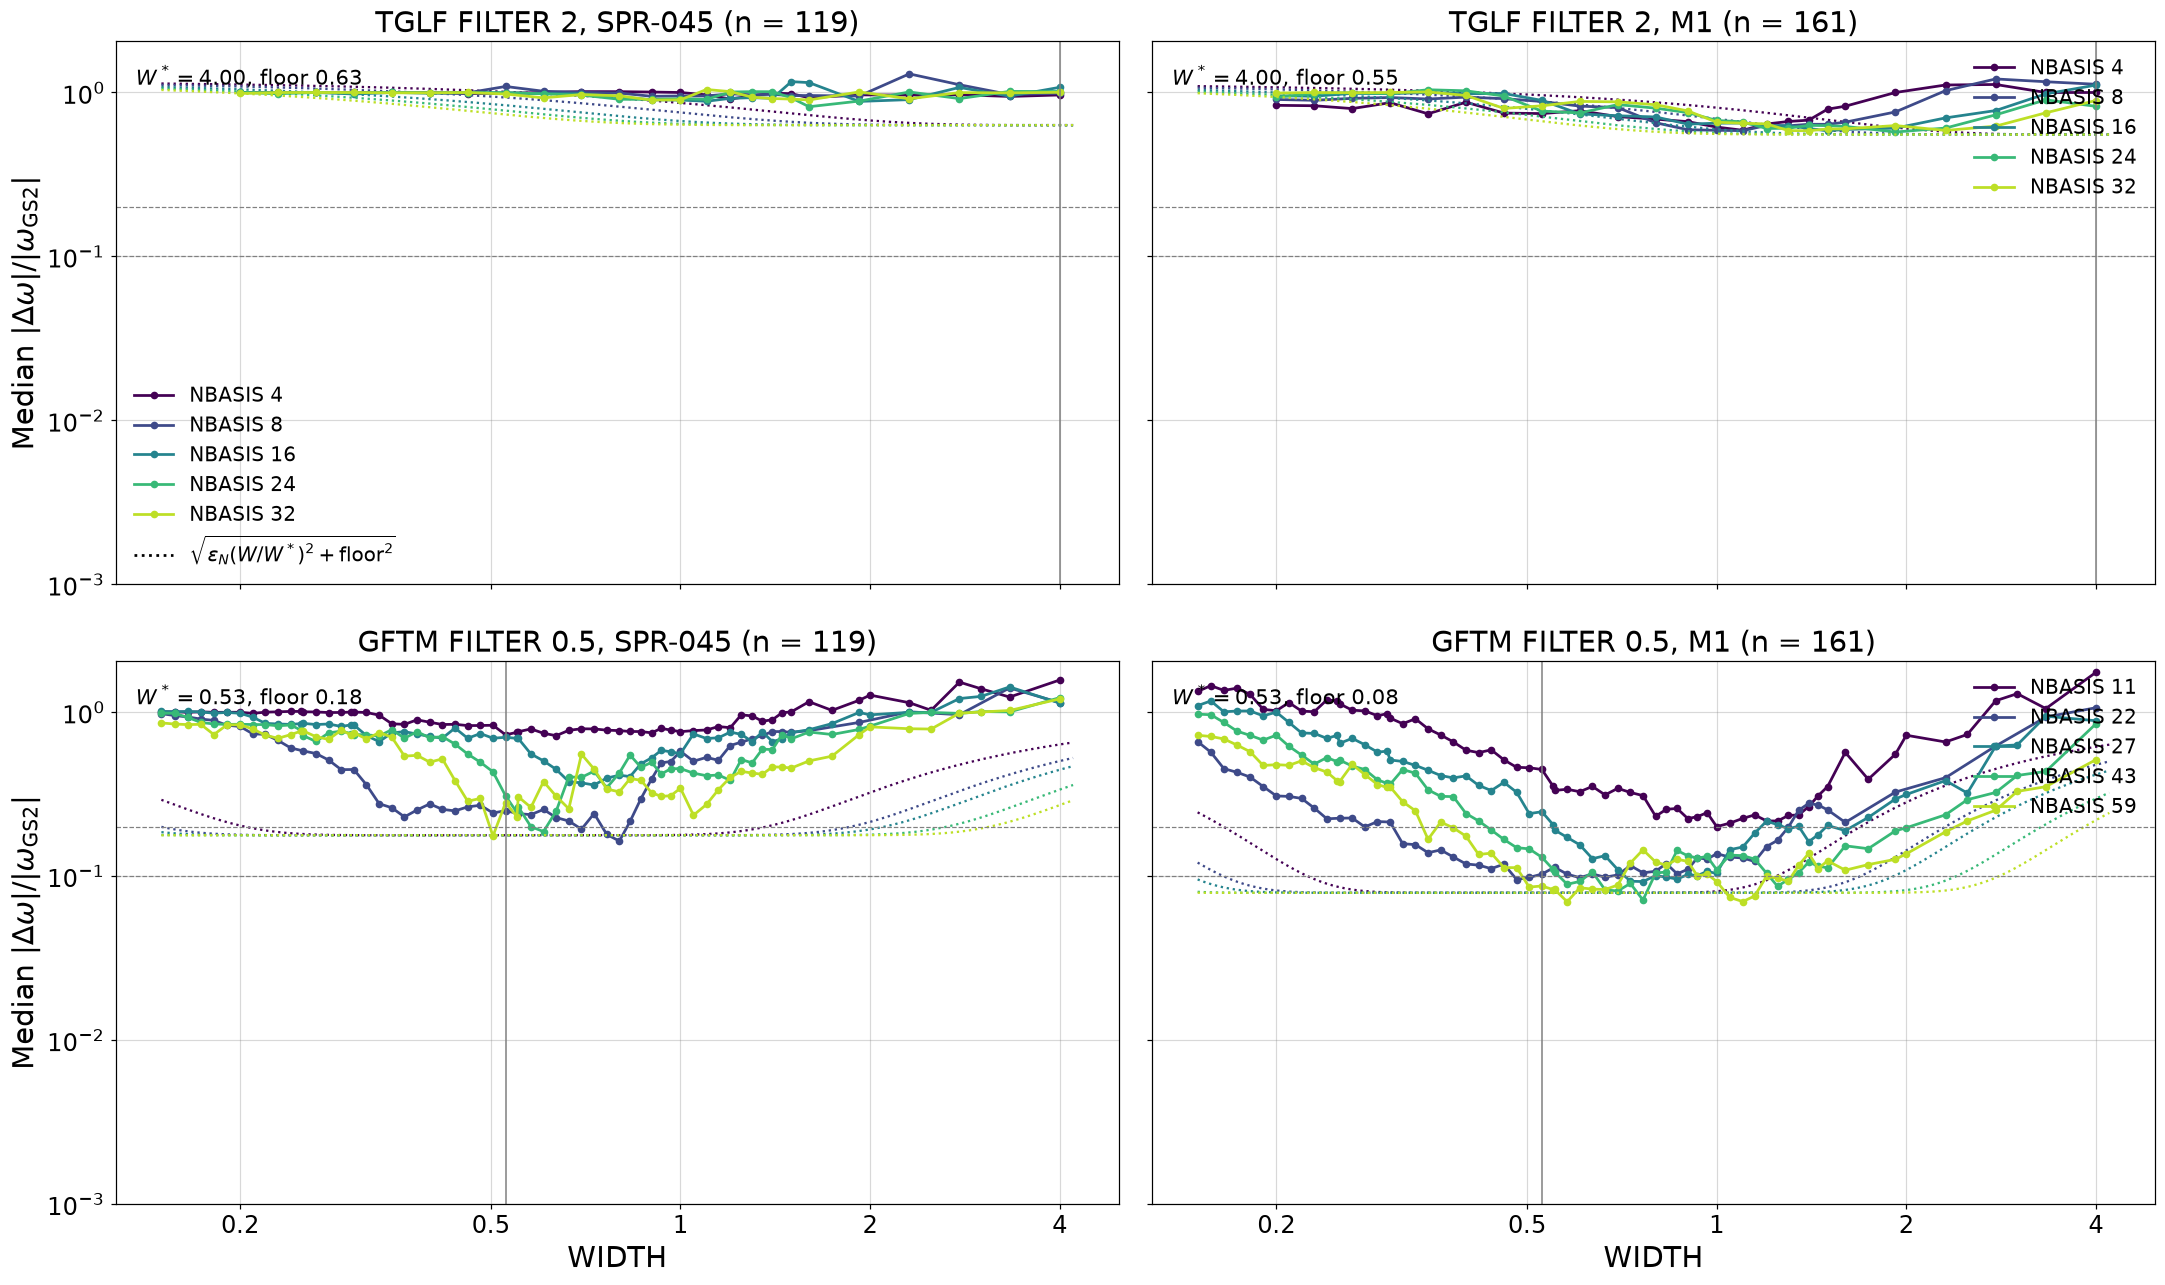

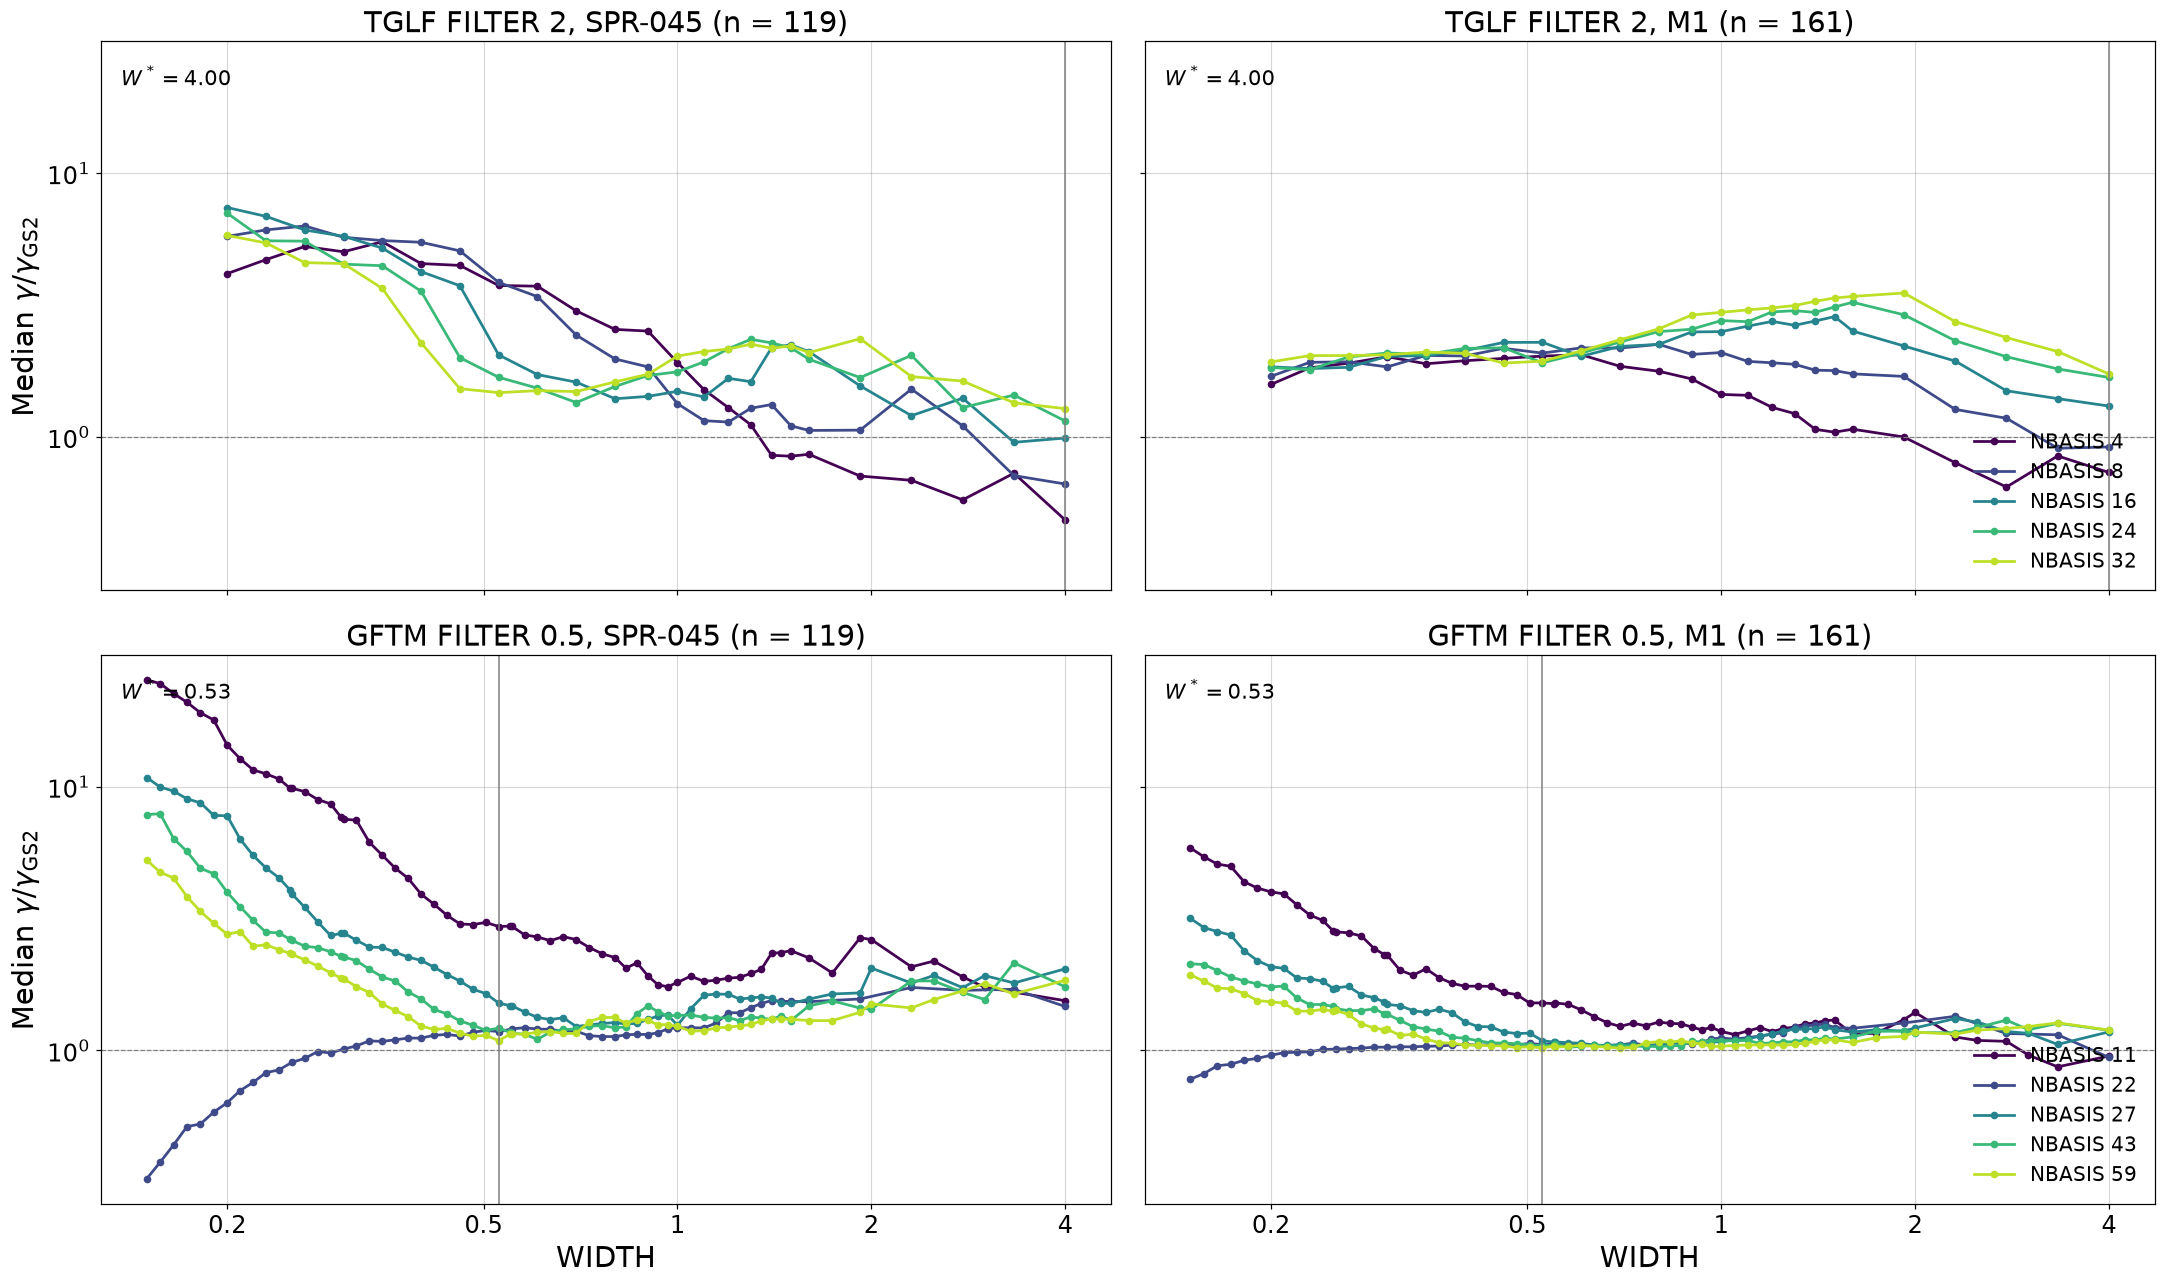

code database  nbasis  threshold  best_width  min_gamma_error  width_lo  width_hi  omega_width_lo  omega_width_hi  self_width_lo  self_width_hi  w_star  floor  gaussian_width_lo  gaussian_width_hi  gaussian_self_lo  gaussian_self_hi
GFTM       M1      11        0.1       1.200            0.226       NaN       NaN             NaN             NaN            NaN            NaN   0.528  0.079              0.224              1.233             0.200             1.393
GFTM       M1      11        0.2       1.200            0.226       NaN       NaN           1.000           1.000          0.900          1.249   0.528  0.079              0.166              1.684             0.160             1.741
GFTM       M1      22        0.1       0.606            0.092     0.606     0.606           0.481           0.504          0.317          1.049   0.528  0.079              0.166              1.684             0.150             1.883
GFTM       M1      22        0.2       0.606            0.092     0.

In [4]:
runs = runs.merge(pd.concat([pd.DataFrame(dict(database=database, sample=gs2[database]["names"], gamma_gs2=gs2[database]["gamma"],
                                                omega_gs2=gs2[database]["omega"])) for database in databases]), on=["database", "sample"])
runs["gamma_error"] = np.abs(runs.gamma / runs.gamma_gs2 - 1)
runs["omega_error"] = np.abs(runs.omega - runs.omega_gs2) / np.abs(runs.omega_gs2)
runs["gamma_ratio"] = runs.gamma / runs.gamma_gs2
medians = runs.groupby(["code", "database", "nbasis", "width"])[["gamma_error", "omega_error", "gamma_ratio"]].median().reset_index()
# theory centre per (code, database): the width of the highest-NBASIS line's minimum; floor: the panel's lowest median error
top_nbasis = {"TGLF": max(tglf_nbasis), "GFTM": max(gftm_sections)}
w_star, floor = {}, {}
for (code, database), d in medians.groupby(["code", "database"]):
    top = d[d.nbasis == top_nbasis[code]]
    w_star[code, database] = top.width.values[top.gamma_error.values.argmin()]
    floor[code, database] = d.gamma_error.min()
print("W* (min of the top-NBASIS line):", w_star, "| floor (panel min median error):", {k: round(v, 3) for k, v in floor.items()})
print("for reference, Gaussian-matched W* = theta95/2.772 of the median GS2 theta95:",
      {d: round(gaussian_c * float(np.median(gs2[d]["theta95"])), 3) for d in databases})

# numerical error only: each sample against the same code's top-NBASIS gamma at W*
reference = runs[[(row.nbasis == top_nbasis[row.code]) and (row.width == w_star[row.code, row.database]) for row in runs.itertuples()]]
runs = runs.merge(reference[["code", "database", "sample", "gamma"]].rename(columns={"gamma": "gamma_ref"}), on=["code", "database", "sample"])
runs["self_error"] = np.abs(runs.gamma / runs.gamma_ref - 1).where(runs.gamma_ref > 0)
medians = medians.merge(runs.groupby(["code", "database", "nbasis", "width"]).self_error.median().reset_index(), on=["code", "database", "nbasis", "width"])
print("samples with a top-NBASIS mode at W*:", (reference.gamma > 0).groupby([reference.code, reference.database]).sum().to_dict())


def window(widths, values, threshold):
    best = int(np.nanargmin(values))
    if values[best] >= threshold:
        return np.nan, np.nan
    lo = hi = best
    while lo > 0 and values[lo - 1] < threshold:
        lo -= 1
    while hi < len(values) - 1 and values[hi + 1] < threshold:
        hi += 1
    return widths[lo], widths[hi]


w_plot = np.logspace(np.log10(0.15), np.log10(4.2), 300)
labels = {"self_error": r"Median $|\gamma/\gamma_{\rm ref} - 1|$",
          "gamma_error": r"Median $|\gamma/\gamma_{\rm GS2} - 1|$", "omega_error": r"Median $|\Delta\omega|/|\omega_{\rm GS2}|$",
          "gamma_ratio": r"Median $\gamma/\gamma_{\rm GS2}$"}
for quantity, name in (("self_error", "fig8_ushape_self_convergence"), ("gamma_error", "fig5_ushape_gamma"), ("omega_error", "fig6_ushape_omega"), ("gamma_ratio", "fig7_gamma_ratio")):
    fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharex=True, sharey=True)
    for row, (code, nbasis_list) in enumerate((("TGLF", tglf_nbasis), ("GFTM", list(gftm_sections)))):
        colours = dict(zip(nbasis_list, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_list)))))
        for ax, database in zip(axes[row], databases):
            for nbasis in nbasis_list:
                d = medians[(medians.code == code) & (medians.database == database) & (medians.nbasis == nbasis)]
                ax.plot(d.width, d[quantity], color=colours[nbasis], marker="o", ms=4, label=f"NBASIS {nbasis}")
                if quantity != "gamma_ratio":
                    # vs GS2 the data cannot fall below the model-error floor: theory = sqrt(eps^2 + floor^2); self-convergence has no floor
                    floor_level = 0 if quantity == "self_error" else floor[code, database]
                    ax.plot(w_plot, np.hypot(gaussian_error(w_plot / w_star[code, database], nbasis), floor_level), color=colours[nbasis],
                            ls=":", lw=1.5, marker="")
            ax.axvline(w_star[code, database], color="0.5", lw=1, marker="")
            ax.text(0.02, 0.92, rf"$W^* = {w_star[code, database]:.2f}$" + ("" if quantity in ("self_error", "gamma_ratio") else
                    f", floor {floor[code, database]:.2f}"), transform=ax.transAxes, fontsize=14)
            for level in ((1.0,) if quantity == "gamma_ratio" else (0.1, 0.2)):
                ax.axhline(level, color="0.5", lw=0.8, ls="--", marker="")
            ax.set(xscale="log", yscale="log", title=f"{code}{f' FILTER {tglf_filter:g}' if code == 'TGLF' else ' FILTER 0.5'}, {database} (n = {len(gs2[database]['names'])})")
            log_xticks(ax, [0.2, 0.5, 1, 2, 4])
        axes[row, 0].set_ylabel(labels[quantity])
        axes[row, 1].legend(loc="lower right" if quantity == "gamma_ratio" else "upper right", ncol=1)
    if quantity != "gamma_ratio":
        axes[0, 0].plot([], [], "k:", label=r"Gaussian $\epsilon_N(W/W^*)$" if quantity == "self_error" else r"$\sqrt{\epsilon_N(W/W^*)^2 + {\rm floor}^2}$")
        axes[0, 0].legend(loc="lower left")
    axes[1, 0].set_ylim(1e-3 if quantity != "gamma_ratio" else None, None)
    for ax in axes[1]:
        ax.set_xlabel("WIDTH")
    if quantity == "self_error":
        fig.suptitle(r"Numerical error only: $\gamma_{\rm ref}$ = same code at its top NBASIS and $W^*$ (no GS2)", fontsize=20)
    fig.tight_layout()
    fig.savefig(plots_dir / f"{name}{suffix}.png", dpi=150)
    plt.show()

rows = []
for (code, database, nbasis), d in medians.groupby(["code", "database", "nbasis"]):
    d = d.sort_values("width")
    for threshold in (0.1, 0.2):
        lo, hi = window(d.width.values, d.gamma_error.values, threshold)
        theory = w_plot[np.hypot(gaussian_error(w_plot / w_star[code, database], nbasis), floor[code, database]) < threshold]
        self_lo, self_hi = window(d.width.values, d.self_error.values, threshold)
        rows.append(dict(code=code, database=database, nbasis=nbasis, threshold=threshold, best_width=d.width.values[d.gamma_error.values.argmin()],
                         min_gamma_error=d.gamma_error.min(), width_lo=lo, width_hi=hi,
                         omega_width_lo=window(d.width.values, d.omega_error.values, threshold)[0],
                         omega_width_hi=window(d.width.values, d.omega_error.values, threshold)[1],
                         self_width_lo=self_lo, self_width_hi=self_hi, w_star=w_star[code, database], floor=floor[code, database],
                         gaussian_width_lo=theory.min() if len(theory) else np.nan, gaussian_width_hi=theory.max() if len(theory) else np.nan,
                         gaussian_self_lo=w_plot[gaussian_error(w_plot / w_star[code, database], nbasis) < threshold].min(),
                         gaussian_self_hi=w_plot[gaussian_error(w_plot / w_star[code, database], nbasis) < threshold].max()))
ushape_windows = pd.DataFrame(rows)
print(ushape_windows.round(3).to_string(index=False))

csv_dir = plots_dir / "csv"
csv_dir.mkdir(exist_ok=True)
selection.to_csv(csv_dir / "dataset_selection.csv", index=False)  # same for every TGLF FILTER
ushape_windows.to_csv(csv_dir / f"ushape_windows{suffix}.csv", index=False, float_format="%.4g")
medians.to_csv(csv_dir / f"ushape_medians{suffix}.csv", index=False, float_format="%.4g")